# Objekterkennung mit ResNet

# Motivation & Problemstellung

Waldbrände und Industriebrände fordern jedes Jahr Tausende von
Menschenleben und verursachen Schäden in Milliardenhöhe. Früherkennung —
innerhalb der ersten Minuten — ist entscheidend für eine erfolgreiche
Eindämmung. Traditionelle Detektionssysteme setzen auf Wärme- oder
Rauchsensoren an festen Punkten. Kamerabasierte Systeme können große
Flächen abdecken, jedoch können menschliche Operatoren nicht Hunderte
von Kamerafeeds gleichzeitig überwachen.

**Die Herausforderung:** die visuelle Signatur von Rauch und Feuer in
realen Bildern automatisch zu erkennen — bei wechselnden
Lichtverhältnissen, komplexen Hintergründen und überlappenden Objekten.

Wir werden eine vollständige Pipeline mit
[ResNet](https://arxiv.org/abs/1512.03385) aufbauen:

1.  ResNet verstehen und von Grund auf implementieren.
2.  Ein auf ImageNet / COCO vortrainiertes Modell laden.
3.  Es auf dem
    [**D-FIRE**-Datensatz](https://github.com/gaia-solutions-on-demand/DFireDataset)
    (~17 000 annotierte Bilder) für die Feuer- und Raucherkennung
    feinabstimmen.

# ResNet in der Geschichte des maschinellen Lernens

## Der ImageNet-Wettbewerb

Der ILSVRC (ImageNet Large Scale Visual Recognition Challenge) war der
Benchmark, der das moderne Computer Vision geprägt hat. Die Aufgabe: 1,2
Millionen Bilder in 1 000 Kategorien klassifizieren.

| Jahr     | Modell          | Top-5-Fehler | Schichten | Kernidee                   |
|------|-------------|-------------|-----------|------------------------------|
| 2011     | Bestes Nicht-DL | 25,8 %       | —         | Handgefertigte Merkmale    |
| 2012     | AlexNet         | 15,3 %       | 8         | Tiefes CNN auf GPU         |
| 2014     | VGGNet          | 7,3 %        | 16–19     | Einheitliche 3×3-Faltungen |
| 2014     | GoogLeNet       | 6,7 %        | 22        | Inception-Module           |
| **2015** | **ResNet**      | **3,57 %**   | **152**   | **Residualverbindungen**   |

ResNets 3,57 % Fehlerrate war das **erste Mal, dass eine Maschine
menschliche Leistung übertraf** auf diesem Benchmark (~5,1 %).

## Warum es das Feld verändert hat

Vor ResNet führte das Stapeln von mehr als ~30 Schichten konsistent zu
schlechterer Genauigkeit — nicht durch Überanpassung, sondern durch ein
fundamentales Optimierungsproblem (siehe Abschnitt 4). ResNet löste
dieses Problem und ermöglichte Netze mit 50, 101 und 152 Schichten.

Die Auswirkungen waren signifikant:

-   **Objektdetektion:** Faster R-CNN, Mask R-CNN, RetinaNet — alle
    verwenden ResNet als Backbone.
-   **Segmentierung:** DeepLab, U-Net-Varianten — ResNet-Encoder.
-   **Medizinische Bildgebung:** Klassifikation von Röntgenaufnahmen,
    Analyse von Pathologiepräparaten.
-   **Vision Transformers:** ViT und Nachfolger verwenden weiterhin
    Residualverbindungen in jedem Block.
-   **Heute:** ResNet-50 bleibt das Standard-Baseline-Backbone in den
    meisten CV-Forschungsarbeiten.

------------------------------------------------------------------------

# PyTorch-Grundlagen

PyTorch ist ein Open-Source-Framework für maschinelles Lernen von Meta
AI, das sich als Standard für Forschung und Produktion durchgesetzt hat.
Es bietet zwei zentrale Funktionalitäten: einen GPU-beschleunigten
Tensor-Rechner (ähnlich NumPy, aber auf der GPU) und eine automatische
Differenzierungsmaschine (Autograd), die Gradienten zur Laufzeit durch
beliebige Berechnungen hindurch verfolgt. Darauf aufbauend stellt
`torch.nn` fertige Schichten, Verlustfunktionen und Optimierer bereit.
Der Code bleibt dabei gewöhnliches Python — kein Kompilierungsschritt,
keine statischen Graphen.

## Tensoren

Ein **Tensor** ist die zentrale Datenstruktur: ein n-dimensionales Array
mit automatischer Differenzierungsunterstützung.

In [2]:
import torch

# 1-D, 2-D, 3-D Tensoren
v = torch.tensor([1.0, 2.0, 3.0])            # Form [3]
M = torch.zeros(3, 4)                        # Form [3, 4]
T = torch.randn(2, 3, 4)                     # Form [2, 3, 4]  — zufällig normalverteilt

print(v.shape, M.shape, T.shape)
print(v.dtype)                               # torch.float32 standardmäßig

# Häufige Operationen
a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
b = torch.ones(2, 2)

print(a + b)
print(a @ b)                                 # Matrizenmultiplikation
print(a.sum(), a.mean())
print(a.reshape(4))                          # Abflachen


torch.Size([3]) torch.Size([3, 4]) torch.Size([2, 3, 4])
torch.float32
tensor([[2., 3.],
        [4., 5.]])
tensor([[3., 3.],
        [7., 7.]])
tensor(10.) tensor(2.5000)
tensor([1., 2., 3., 4.])

Hinweis: Bilder in PyTorch werden immer als
`[batch, channels, height, width]` gespeichert bzw. für die CNN-Modelle
benötigt. Im Allgemeinen werden immer Stapel (batches) von Bildern
bearbeitet.

In [2]:
from PIL import Image
import torchvision.transforms.functional as F

# Bild laden und in Tensor umwandeln
img    = Image.open("Daten/ResNet/Bild_01.jpeg").convert("RGB")  # PIL-Bild, Wertebereich 0–255
tensor = F.to_tensor(img)                               # → [3, H, W], Wertebereich 0.0–1.0

print(f"Bildgröße (PIL)    : {img.size}")                   # (Breite, Höhe)
print(f"Tensor-Form        : {tensor.shape}")               # [3, H, W]
img_min, img_max = img.getextrema()[0]
print(f"Wertebereich Bild  : {img_min:.2f} – {img_max:.2f}")
print(f"Wertebereich Tensor: {tensor.min():.2f} – {tensor.max():.2f}")

# Batch-Dimension hinzufügen, wie ein CNN-Modell es erwartet
batch = tensor.unsqueeze(0)                             # [1, 3, H, W]
print(f"Mit Batch-Dim      : {batch.shape}")

Bildgröße (PIL)    : (4032, 3024)
Tensor-Form        : torch.Size([3, 3024, 4032])
Wertebereich Bild  : 0.00 – 255.00
Wertebereich Tensor: 0.00 – 1.00
Mit Batch-Dim      : torch.Size([1, 3, 3024, 4032])

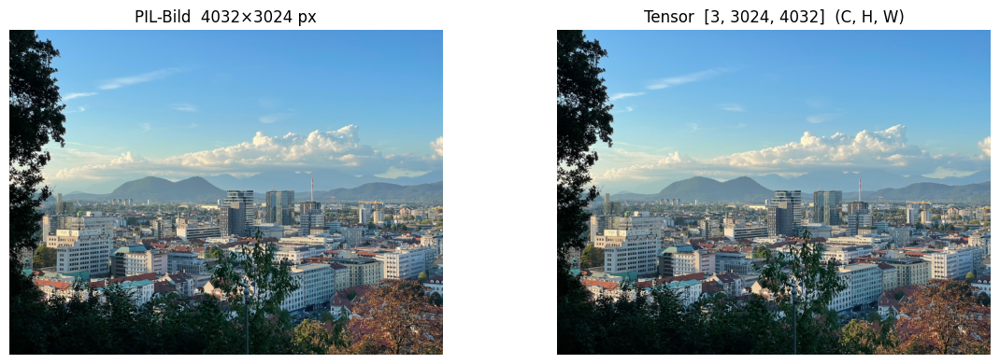

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Originalbild (PIL)
axes[0].imshow(img)
axes[0].set_title(f"PIL-Bild  {img.size[0]}×{img.size[1]} px")
axes[0].axis("off")

# Tensor als Bild (Kanäle zurück nach hinten)
axes[1].imshow(tensor.permute(1, 2, 0))
axes[1].set_title(f"Tensor  {list(tensor.shape)}  (C, H, W)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Autograd: Automatische Differentiation

Neuronales Netztraining basiert grundlegend auf Gradientenabstieg.
PyTorch verfolgt Operationen auf Tensoren mit `requires_grad=True` und
berechnet Gradienten automatisch mit `.backward()`.

**Hinweis** — `requires_grad` und Inferenz-Modus `requires_grad=False`
ist der **Standard** für gewöhnliche Tensoren. PyTorch verfolgt den
Gradienten nur dort, wo es explizit aktiviert wird — Eingabedaten und
Labels brauchen es nicht. Ausnahme: **Modellparameter** (`nn.Parameter`)
haben immer `requires_grad=True` — das macht sie trainierbar.

Bei der **Inferenz** (Vorhersage ohne Training) sollte kein Graph
aufgebaut werden:

| Modus | Verwendung |
|------------------------------------|------------------------------------|
| `@torch.no_grad()` | Validierungsschleifen |
| `@torch.inference_mode()` | Reine Inferenz — schneller, da noch mehr Overhead wegfällt |

In [4]:
import torch

# f(x) = x^2 + 2x + 1 = (x + 1)^2  →  df/dx = 2x + 2
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2*x + 1

y.backward()                               # df/dx bei x berechnen
print(f"x        = {x.item()}")
print(f"y(x)     = {y.item()}")
print(f"dy/dx(x) = {x.grad.item()}")       # Erwartet: 2*(3) + 2 = 8

x        = 3.0
y(x)     = 16.0
dy/dx(x) = 8.0

Für Netze baut PyTorch während des Vorwärtsdurchlaufs einen
Berechnungsgraphen auf und durchläuft ihn rückwärts, um Gradienten in
jedem `.grad`-Attribut der Parameter anzusammeln.

## Neuronale Netze aufbauen

Jede Schicht, jeder Block und jedes vollständige Modell erbt von
`nn.Module`. Parameter werden in `__init__` definiert, die
Vorwärtsberechnung in `forward`.

In [3]:
import torch
import torch.nn as nn

class TinyMLP(nn.Module):
    def __init__(self, in_features, hidden, out_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_features),
        )

    def forward(self, x):
        return self.net(x)


model = TinyMLP(in_features=2, hidden=8, out_features=1)

x = torch.randn(4, 2)           # Batch von 4 Samples, 2 Merkmale je Sample
print(model(x).shape)           # [4, 1]

# Parameter inspizieren
for name, p in model.named_parameters():
    print(f"{name:20s}  shape={list(p.shape)}")


torch.Size([4, 1])
net.0.weight          shape=[8, 2]
net.0.bias            shape=[8]
net.2.weight          shape=[1, 8]
net.2.bias            shape=[1]

Die Ausgabe listet alle vier Parametertensoren des `TinyMLP`. Die Zahlen
ergeben sich direkt aus der Architektur:

``` python
nn.Linear(in_features=2, hidden=8, out_features=1)
```

| Name | Form | Bedeutung |
|------------------------|------------------------|------------------------|
| `net.0.weight` | `[8, 2]` | Gewichtsmatrix der ersten Linear-Schicht: 8 Neuronen, je 2 Eingaben |
| `net.0.bias` | `[8]` | Ein Bias pro Neuron der ersten Schicht |
| `net.2.weight` | `[1, 8]` | Gewichtsmatrix der zweiten Linear-Schicht: 1 Ausgabe, 8 Eingaben |
| `net.2.bias` | `[1]` | Ein Bias für das einzelne Ausgabeneuron |

Die Indizes 0 und 2 (nicht 0 und 1) kommen von `nn.Sequential` — es
nummeriert die Elemente nach Position, und `ReLU` sitzt an Index 1. Da
ReLU keine Parameter hat, taucht es in der Ausgabe nicht auf:

    net.0  →  Linear(2 → 8)
    net.1  →  ReLU           ← keine Parameter, nicht angezeigt
    net.2  →  Linear(8 → 1)

## Warum GPUs schneller sind

### Der Hardwareunterschied

Allgemein:

| Eigenschaft | CPU | GPU |
|------------------------|------------------------|------------------------|
| Kerne | 8 – 64 leistungsstarke Kerne | Tausende kleiner Kerne |
| Optimiert für | Sequenziellen, verzweigten Code | Massiv parallelen, regulären Code |
| Taktfrequenz | ~3–5 GHz | ~1–2 GHz pro Kern |
| Speicherbandbreite | ~50 GB/s (DDR5) | ~400–1000 GB/s (VRAM) |

Konkrete Beispiele über drei Generationen:

| Eigenschaft | CPU ~2015 | CPU ~2020 | CPU ~2024 |
|------------------|------------------|------------------|------------------|
| Modell | Intel Core i7-6700K | AMD Ryzen 9 5950X | AMD Ryzen 9 9950X |
| Kerne | 4 | 16 | 16 |
| Taktfrequenz (Boost) | ~4,2 GHz | ~4,9 GHz | ~5,7 GHz |
| Speicherbandbreite | ~34 GB/s (DDR4) | ~51 GB/s (DDR4) | ~67 GB/s (DDR5) |
| FP32 Peak (TFLOPS) | ~0,27 (AVX2+FMA) | ~1,3 (AVX2+FMA) | ~2,9 (AVX-512+FMA) |

| Eigenschaft | GPU ~2015 | GPU ~2020 | GPU ~2024 | KI ~2024 | KI ~2025 |
|------------|------------|------------|------------|------------|------------|
| Modell | GTX 980 Ti | RTX 3080 | RTX 4090 | **H100 SXM** | **B200 SXM** |
| Klasse | Consumer | Consumer | Consumer | Rechenzentrum | Rechenzentrum |
| Architektur | Maxwell | Ampere | Ada Lovelace | Hopper | Blackwell |
| CUDA-Kerne | 2 816 | 8 704 | 16 384 | 16 896 | 20 480 |
| Taktfrequenz (Boost) | ~1,1 GHz | ~1,7 GHz | ~2,5 GHz | ~1,98 GHz | ~1,8 GHz |
| Speicherbandbreite | 336 GB/s | 760 GB/s | 1 008 GB/s | 3 350 GB/s (HBM3) | **8 000 GB/s** (HBM3e) |
| VRAM | 6 GB | 10 GB | 24 GB | 80 GB | **192 GB** |
| FP32 Peak (TFLOPS) | 5,6 | 29,8 | 82,6 | 67 | ~74 |
| Tensor Core KI-Peak (TFLOPS) | — (keine) | 120 ¹ | 330 ¹ | **1 979** ¹ (FP16) | **9 000** ² (FP8) |
| Preis (ca.) | 700 € | 700 € | 1 700 € | ~30 000 € | ~45 000 € |

¹ Mit Sparsity (NVIDIA-Standardangabe). ² FP8 mit Sparsity (B200
veröffentlicht kein FP16-Tensor-Core-Wert).

**GB200 NVL72 — Rack-Scale-System (2025)** Das GB200 NVL72 ist kein
einzelner Chip, sondern ein vollständiges Rack: 72 B200-GPUs + 36
Grace-CPUs, verbunden über NVLink 5.0. Kennzahlen des gesamten Racks: -
Speicherbandbreite gesamt: **576 TB/s** - VRAM gesamt: **13,5 TB**
HBM3e - NVLink-Bandbreite (GPU–GPU): 130 TB/s - Preis: ~3 Mio. USD pro
Rack

Solche Systeme werden genutzt, um Modelle mit Billionen von Parametern
zu trainieren — ein einzelnes Rack entspricht der Rechenleistung von
mehreren tausend Consumer-GPUs.

### Warum neuronale Netze GPUs lieben

Jeder Vorwärts- und Rückwärtsdurchlauf wird von
**Matrizenmultiplikation** dominiert:

$$\mathbf{y} = \mathbf{W}\mathbf{x} + \mathbf{b}$$

Die Multiplikation einer 1000 × 1000-Gewichtsmatrix mit einem
1000-elementigen Eingangsvektor erfordert 1 000 000
Multiplikations-Akkumulationsoperationen — alle **voneinander
unabhängig**, sodass eine GPU sie alle gleichzeitig ausführen kann.

Eine CPU muss sie (annähernd) sequenziell durchführen. Eine moderne GPU
besitzt Tausende von *CUDA-Kernen*, die je eine Multiplikation
gleichzeitig erledigen.

### (OPTIONAL) Tensoren in PyTorch auf die GPU verschieben

In [4]:
import platform
import os
import torch

print("=== CPU / System ===")
print(f"OS:         {platform.system()} {platform.release()} ({platform.machine()})")
try:
    import psutil
    phys = psutil.cpu_count(logical=False)
    logi = psutil.cpu_count(logical=True)
    freq = psutil.cpu_freq()
    mem  = psutil.virtual_memory()
    print(f"Processor:  {platform.processor() or 'n/a'}")
    print(f"CPU cores:  {phys} physical, {logi} logical")
    if freq:
        print(f"CPU freq:   {freq.current:.0f} MHz  (max {freq.max:.0f} MHz)")
    print(f"RAM:        {mem.total / 1024**3:.1f} GB  ({mem.available / 1024**3:.1f} GB available)")
except ImportError:
    print(f"Processor:  {platform.processor() or 'n/a'}")
    print(f"CPU cores:  {os.cpu_count()} logical  (install psutil for more detail)")

print()
print("=== GPU ===")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"CUDA GPU {i}: {p.name}")
        print(f"  VRAM:       {p.total_memory / 1024**3:.1f} GB")
        print(f"  Compute:    {p.major}.{p.minor}  |  SMs: {p.multi_processor_count}")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    print("Apple MPS (Metal Performance Shaders): available")
    if platform.system() == "Darwin":
        import subprocess
        out = subprocess.run(
            ["system_profiler", "SPDisplaysDataType"],
            capture_output=True, text=True
        ).stdout
        for line in out.splitlines():
            if any(k in line for k in ("Chipset Model", "VRAM", "Metal")):
                print(" ", line.strip())
else:
    print("No GPU detected (no CUDA, no Apple MPS)")

print()
print(f"PyTorch version: {torch.__version__}")


=== CPU / System ===
OS:         Darwin 25.5.0 (arm64)
Processor:  arm
CPU cores:  10 physical, 10 logical
CPU freq:   3228 MHz  (max 3228 MHz)
RAM:        32.0 GB  (7.6 GB available)

=== GPU ===
Apple MPS (Metal Performance Shaders): available
  Chipset Model: Apple M1 Max
  Metal Support: Metal 4

PyTorch version: 2.12.0

In [7]:
import torch
import time

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Ausgewähltes Gerät: {device}")

size = 4096
print(f"Matrix Größe: {size}×{size}")

A = torch.randn(size, size)
B = torch.randn(size, size)

# Auf der CPU
t0 = time.perf_counter()
C_cpu = A @ B
cpu_time = time.perf_counter() - t0
print(f"CPU: {cpu_time:.3f} s")

# Auf der GPU / MPS (falls verfügbar)
if device.type != "cpu":
    A_acc = A.to(device)
    B_acc = B.to(device)

    # Einmal warm laufen lassen (JIT-Kompilierung / Speicherallokation)
    _ = A_acc @ B_acc
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

    t0 = time.perf_counter()
    C_acc = A_acc @ B_acc
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    acc_time = time.perf_counter() - t0

    label = "GPU (CUDA)" if device.type == "cuda" else "GPU (MPS)"
    print(f"{label}: {acc_time:.3f} s")
    print(f"Speedup: {cpu_time / acc_time:.1f}×")
else:
    print("Keine GPU verfügbar — GPU-Block übersprungen.")


Ausgewähltes Gerät: mps
Matrix Größe: 4096×4096
CPU: 0.085 s
GPU (MPS): 0.016 s
Speedup: 5.2×

> **Note**
>
> Tensoren müssen auf demselben Gerät liegen. Das Mischen von CPU- und
> GPU-Tensoren führt zu einem Fehler. Der Datentransfer selbst
> (`.to(device)`) kostet Zeit — beim Training sollten Batches direkt auf
> die GPU geladen werden, statt sie einzeln zu verschieben.

## Eine minimale Trainingsschleife

In [8]:
import torch
import torch.nn as nn

torch.manual_seed(0)

# Grundwahrheit: y = 3x + 2, mit Rauschen
X = torch.randn(100, 1)
y = 3 * X + 2 + 0.3 * torch.randn(100, 1)

model     = nn.Linear(1, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn   = nn.MSELoss()

for epoch in range(51):
    pred = model(X)
    loss = loss_fn(pred, y)

    optimizer.zero_grad()    # alte Gradienten löschen
    loss.backward()          # neue Gradienten berechnen
    optimizer.step()         # Parameter aktualisieren

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d}  loss={loss.item():.4f}")

w = model.weight.item()
b = model.bias.item()
print(f"\nGelernt: y = {w:.2f}x + {b:.2f}  (wahr: y = 3.00x + 2.00)")

Epoch   0  loss=10.1185
Epoch  10  loss=0.1568
Epoch  20  loss=0.0759
Epoch  30  loss=0.0753
Epoch  40  loss=0.0753
Epoch  50  loss=0.0753

Gelernt: y = 2.96x + 2.05  (wahr: y = 3.00x + 2.00)

Diese innere Schleife — `forward → loss → zero_grad → backward → step` —
ist das Gerüst jeder Trainingsschleife.

# Das Tiefenproblem bei einfachen CNNs

## Kurze CNN-Zusammenfassung

Ein Convolutional Neural Network ist eine Abfolge aus:

-   **Faltungsschichten (Convolutional layers):** lernen lokale
    Merkmalsdetektoren (Kanten, Texturen, Muster).
-   **Pooling-Schichten:** reduzieren die räumliche Auflösung.
-   **Vollverbundene Schichten (Fully-connected layers):** bilden
    Merkmale auf Klassenscores ab.

Frühe Schichten erkennen niederstufige Merkmale (Kanten, Farben).
Tiefere Schichten erkennen hochstufige Konzepte (Augen, Räder,
Rauchfahnen). Mehr Tiefe → reichhaltigere Repräsentationen.

## Warum das einfache Hinzufügen von Schichten scheitert

Die Intuition sagt: *tiefer = besser*. In der Praxis produziert das
Training eines 56-schichtigen einfachen Netzes jedoch einen **höheren
Trainingsfehler** als ein 20-schichtiges — kein Overfitting, sondern ein
Optimierungsversagen.

Die eigentliche Ursache sind **verschwindende Gradienten**. Beim
Backpropagation werden Gradienten durch jede Schicht über die
Kettenregel multipliziert. Wenn jede Schicht den Gradienten auch nur
geringfügig verringert, nähert sich das Produkt über 50 Schichten null:

In [9]:
import torch

def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

def sigmoid_grad(x):
    s = sigmoid(x)
    return s * (1 - s)      # Maximalwert ist 0,25

x = torch.tensor(0.0)
grad = torch.tensor(1.0)

for i in range(1, 21):
    grad = grad * sigmoid_grad(x)
    print(f"Nach Schicht {i:2d}: Gradient = {grad.item():.8f}")

Nach Schicht  1: Gradient = 0.25000000
Nach Schicht  2: Gradient = 0.06250000
Nach Schicht  3: Gradient = 0.01562500
Nach Schicht  4: Gradient = 0.00390625
Nach Schicht  5: Gradient = 0.00097656
Nach Schicht  6: Gradient = 0.00024414
Nach Schicht  7: Gradient = 0.00006104
Nach Schicht  8: Gradient = 0.00001526
Nach Schicht  9: Gradient = 0.00000381
Nach Schicht 10: Gradient = 0.00000095
Nach Schicht 11: Gradient = 0.00000024
Nach Schicht 12: Gradient = 0.00000006
Nach Schicht 13: Gradient = 0.00000001
Nach Schicht 14: Gradient = 0.00000000
Nach Schicht 15: Gradient = 0.00000000
Nach Schicht 16: Gradient = 0.00000000
Nach Schicht 17: Gradient = 0.00000000
Nach Schicht 18: Gradient = 0.00000000
Nach Schicht 19: Gradient = 0.00000000
Nach Schicht 20: Gradient = 0.00000000

Ab Schicht 10 ist der Gradient bereits vernachlässigbar klein — frühere
Schichten lernen im Wesentlichen nicht mehr. Die Residualverbindung ist
die direkte Lösung für dieses Problem.

# ResNet: Die Residualverbindung

## Die Kernidee

Anstatt eine direkte Abbildung $\mathcal{H}(x)$ zu lernen, lernt ein
Residualblock das **Residuum** $\mathcal{F}(x) = \mathcal{H}(x) - x$,
sodass:

$$\mathcal{H}(x) = \mathcal{F}(x) + x$$

Das $+\, x$ ist die **Skip-Verbindung** (auch Shortcut genannt). Beim
Backpropagation fließen Gradienten durch den Shortcut-Pfad
**unverändert** — das Problem der verschwindenden Gradienten wird
umgangen.

<figure>
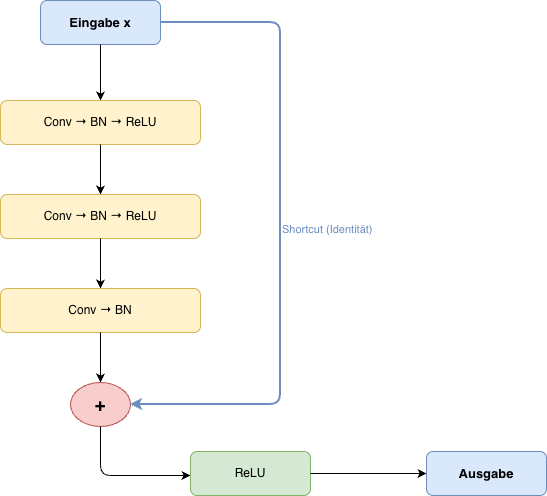
<figcaption aria-hidden="true">Aufbau eines Bottleneck-Residualblocks
(ResNet-50). Der Shortcut (blaue Linie rechts) überbrückt die drei
Faltungsschichten und addiert die Eingabe direkt zur Ausgabe des letzten
Conv→BN, bevor das abschließende ReLU angewendet wird.</figcaption>
</figure>

Wenn sich die Dimensionen ändern (unterschiedliche Anzahl von Kanälen
oder räumliches Downsampling), verwendet der Shortcut eine 1×1-Faltung
zur Anpassung.

## Zwei Grundbausteine

| Block        | Verwendet in        | Faltungen       | Kanäle                |
|--------------|---------------------|-----------------|-----------------------|
| `BasicBlock` | ResNet-18, 34       | 3×3 → 3×3       | ein → ein             |
| `Bottleneck` | ResNet-50, 101, 152 | 1×1 → 3×3 → 1×1 | ein → mitte → 4×mitte |

Der **Bottleneck** verwendet eine 1×1-Faltung, um Kanäle vor der teuren
3×3-Faltung zu *reduzieren* und sie dann mit einer weiteren 1×1-Faltung
wieder zu *erweitern*. Dies reduziert den Rechenaufwand um ~4× im
Vergleich zum Stapeln von zwei 3×3-Faltungen.

## ResNet-50 Schichtenübersicht

| Stage   | Blöcke | Blocktyp   | Ausgabegröße | Kanäle |
|---------|--------|------------|--------------|--------|
| Stem    | 1      | 7×7 conv   | 112 × 112    | 64     |
| MaxPool | 1      | 3×3        | 56 × 56      | 64     |
| layer1  | 3      | Bottleneck | 56 × 56      | 256    |
| layer2  | 4      | Bottleneck | 28 × 28      | 512    |
| layer3  | 6      | Bottleneck | 14 × 14      | 1 024  |
| layer4  | 3      | Bottleneck | 7 × 7        | 2 048  |
| AvgPool | 1      | Adaptiv    | 1 × 1        | 2 048  |
| FC      | 1      | Linear     | —            | 1 000  |

3 + 4 + 6 + 3 = **16 Bottleneck-Blöcke × 3 Faltungen je = 48
Faltungsschichten + Stem + FC = 50**. Daher kommt der Name ResNet-50.

Das folgende Beispiel demonstriert die Klassifizierung eines ResNet-50
Netzes, welches anhand von ImageNet Bildern/Klassen trainiert wurde.

 Kategorien:  ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich', 'brambling', 'goldfinch', 'house finch', 'junco', 'indigo bunting', 'robin', 'bulbul', 'jay', 'magpie', 'chickadee', 'water ouzel', 'kite', 'bald eagle', 'vulture', 'great grey owl', 'European fire salamander', 'common newt', 'eft', 'spotted salamander', 'axolotl', 'bullfrog', 'tree frog', 'tailed frog', 'loggerhead', 'leatherback turtle', 'mud turtle', 'terrapin', 'box turtle', 'banded gecko', 'common iguana', 'American chameleon', 'whiptail', 'agama', 'frilled lizard', 'alligator lizard', 'Gila monster', 'green lizard', 'African chameleon', 'Komodo dragon', 'African crocodile', 'American alligator', 'triceratops', 'thunder snake', 'ringneck snake', 'hognose snake', 'green snake', 'king snake', 'garter snake', 'water snake', 'vine snake', 'night snake', 'boa constrictor', 'rock python', 'Indian cobra', 'green mamba', 'sea snake', 'horned viper', '

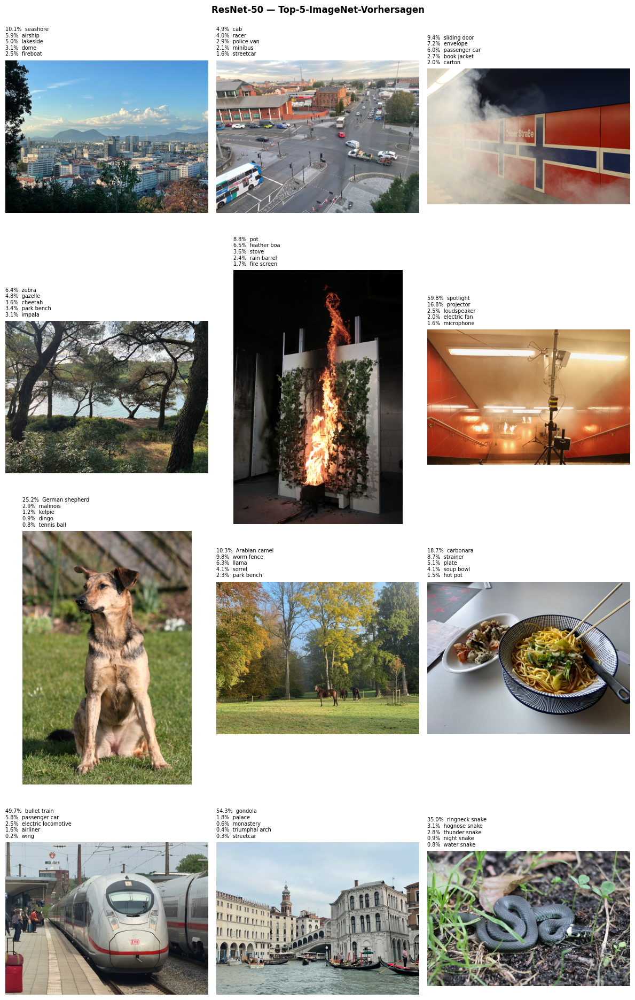

In [5]:
import glob
import torch
import torchvision
import torchvision.transforms.functional as F
from PIL import Image
import matplotlib.pyplot as plt

weights = torchvision.models.ResNet50_Weights.DEFAULT # Trainierte Gewichte laden 
model   = torchvision.models.resnet50(weights=weights) # ResNet-50 Architektur erzeugen und mit Gewichtswerten füllen
model.eval()                              # Setze Modell in Auswerte-Modus

categories = weights.meta["categories"]   # Liste mit 1000 ImageNet-Klassenbezeichnungen
print(" Kategorien: ", categories)
n = 10
lines = [', '.join(categories[i:i+n]) for i in range(0, len(categories), n)]
print(f"ImageNet Kategorien ({len(categories)}):\n" + '\n'.join(lines))

preprocess = weights.transforms()         # Standard-ImageNet-Resize + Crop + Normalisierung

image_paths = sorted(glob.glob("Daten/ResNet/Bild_??.jpeg"))


@torch.inference_mode()                          # Keine Gradientenberechnung -> Inference Modus
def classify_top5(img_path):
    img    = Image.open(img_path).convert("RGB")
    tensor = preprocess(img).unsqueeze(0)        # [1, 3, 224, 224]
    logits = model(tensor)[0]
    probs  = torch.softmax(logits, dim=0)

    top5_probs, top5_idx = probs.topk(5)
    return img, [(categories[i], p.item()) for i, p in zip(top5_idx, top5_probs)]


ncols = min(3, len(image_paths))
nrows = (len(image_paths) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 5 * nrows), squeeze=False)
axes = axes.flatten()

for ax, path in zip(axes, image_paths):
    img, top5 = classify_top5(path)
    ax.imshow(img)
    ax.axis("off")
    label = "\n".join(f"{p*100:.1f}%  {name}" for name, p in top5)
    ax.set_title(label, fontsize=7, loc="left")

for ax in axes[len(image_paths):]:
    ax.axis("off")

plt.suptitle("ResNet-50 — Top-5-ImageNet-Vorhersagen", fontweight="bold")
plt.tight_layout()
plt.show()


## Aufgabe 2 — Objektdetektion mit Faster R-CNN

ResNet-50 allein ist ein Klassifikator — ein Label für das gesamte Bild.
Als Backbone in Faster R-CNN eingebunden wird es zum **Detektor**: es
lokalisiert und beschriftet mehrere Objekte pro Bild mit
Begrenzungsrahmen.

<figure>
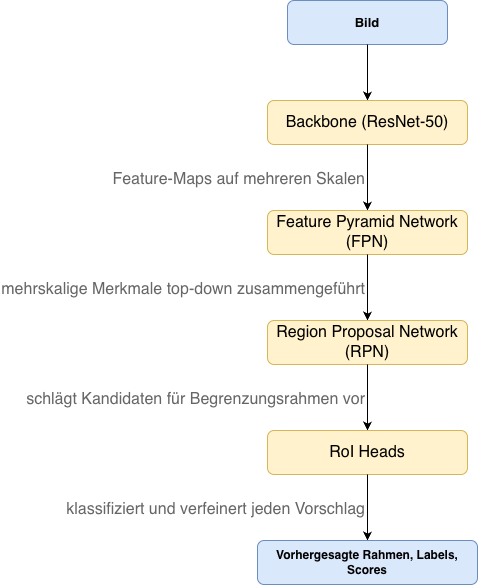
<figcaption aria-hidden="true">Faster R-CNN-Pipeline: Das Eingabebild
durchläuft den ResNet-50-Backbone und das Feature Pyramid Network (FPN),
welches Merkmalskarten auf mehreren Skalen erzeugt. Das Region Proposal
Network (RPN) schlägt ~2 000 Kandidaten-Begrenzungsrahmen vor; die
RoI-Heads klassifizieren und verfeinern jeden Vorschlag zu den
endgültigen Detektionsergebnissen (Rahmen, Labels, Scores).</figcaption>
</figure>

> **Aufgabe 2 — COCO-Detektion**
>
> Laden Sie
> `torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")`
> und führen Sie es auf jedem Bild aus. Zeichnen Sie Begrenzungsrahmen
> für alle Detektionen mit einem Konfidenz-Score ≥ 0,6. Beschriften Sie
> jeden Rahmen mit dem COCO-Klassennamen und dem Score.
>
> Verwenden Sie `FasterRCNN_ResNet50_FPN_Weights.DEFAULT`, um die
> COCO-Kategorieliste abzurufen.

COCO Kategorien (91):
__background__, person, bicycle, car, motorcycle, airplane, bus, train, truck, boat
traffic light, fire hydrant, N/A, stop sign, parking meter, bench, bird, cat, dog, horse
sheep, cow, elephant, bear, zebra, giraffe, N/A, backpack, umbrella, N/A
N/A, handbag, tie, suitcase, frisbee, skis, snowboard, sports ball, kite, baseball bat
baseball glove, skateboard, surfboard, tennis racket, bottle, N/A, wine glass, cup, fork, knife
spoon, bowl, banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza
donut, cake, chair, couch, potted plant, bed, N/A, dining table, N/A, N/A
toilet, N/A, tv, laptop, mouse, remote, keyboard, cell phone, microwave, oven
toaster, sink, refrigerator, N/A, book, clock, vase, scissors, teddy bear, hair drier
toothbrush

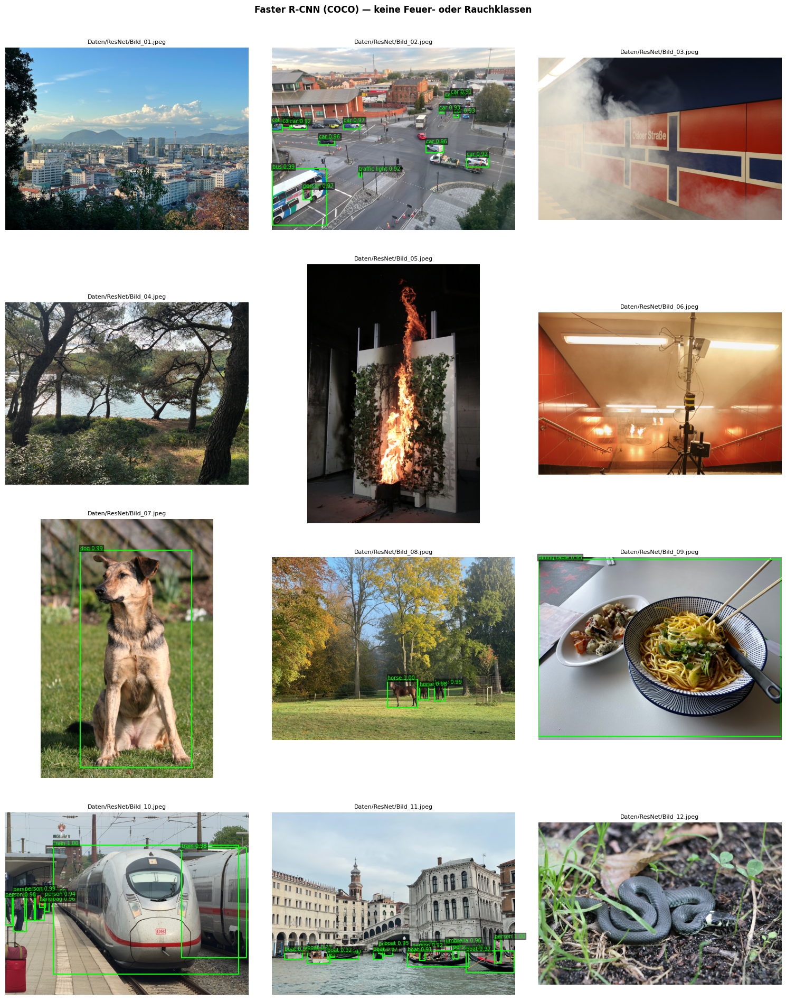

In [7]:

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights,
)
import matplotlib.patches as patches

det_weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
detector    = fasterrcnn_resnet50_fpn(weights=det_weights)
detector.eval()

coco_categories = det_weights.meta["categories"]
n = 10
lines = [', '.join(coco_categories[i:i+n]) for i in range(0, len(coco_categories), n)]
print(f"COCO Kategorien ({len(coco_categories)}):\n" + '\n'.join(lines))

@torch.inference_mode()
def detect(img_path, score_thresh=0.9):
    img    = Image.open(img_path).convert("RGB")
    tensor = F.to_tensor(img)                  # [0, 1] float, keine Normalisierung nötig
    out    = detector([tensor])[0]

    keep = out["scores"] >= score_thresh
    return img, {
        "boxes":  out["boxes"][keep],
        "labels": out["labels"][keep],
        "scores": out["scores"][keep],
    }


ncols = min(3, len(image_paths))
nrows = (len(image_paths) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
axes = axes.flatten()

for ax, path in zip(axes, image_paths):
    img, det = detect(path)
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(path, fontsize=8)

    for box, label, score in zip(det["boxes"], det["labels"], det["scores"]):
        x1, y1, x2, y2 = box.tolist()
        name = coco_categories[label.item()]
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor="lime", facecolor="none"
        ))
        ax.text(x1, max(0, y1 - 4), f"{name} {score:.2f}",
                fontsize=7, color="lime",
                bbox=dict(facecolor="black", alpha=0.5, pad=1))

for ax in axes[len(image_paths):]:
    ax.axis("off")

plt.suptitle("Faster R-CNN (COCO) — keine Feuer- oder Rauchklassen", fontweight="bold")
plt.tight_layout()
plt.show()


# Der D-FIRE-Datensatz

## Überblick

D-FIRE ist ein offener Datensatz mit 21 527 Bildern aus öffentlichen und
synthetischen Quellen, annotiert für die **Objektdetektion** von Feuer
und Rauch.

-   **Trainings-Split:** ~17 221 Bilder
-   **Test-Split:** ~4 306 Bilder
-   **Labels:** YOLO-Format — eine `.txt`-Datei pro Bild, eine Zeile pro
    Begrenzungsrahmen

## YOLO-Labelformat

Jede Label-Datei enthält Zeilen der Form:

    <class_id>  <x_center>  <y_center>  <width>  <height>

Alle Koordinaten sind **normalisiert** (0–1) relativ zu den
Bildabmessungen.

| class_id | Bedeutung |
|----------|-----------|
| 0        | Rauch     |
| 1        | Feuer     |

Eine leere `.txt`-Datei bedeutet, dass sich kein Feuer oder Rauch in
diesem Bild befindet.

## Aufgabe 3 — Eine Stichprobe visualisieren

> **Aufgabe 3 — D-Fire Datensatz erkunden**
>
> Laden Sie ein zufälliges Bild aus `D-Fire/train/images/`, parsen Sie
> die zugehörige Label-Datei und zeichnen Sie die Begrenzungsrahmen mit
> `matplotlib.patches.Rectangle`. Färben Sie Rauch-Rahmen cyan und
> Feuer-Rahmen rot. Drucken Sie den Dateinamen und die vorhandenen
> Klassen aus.

In [8]:
# Pfad zum D-FIRE Bilderdatensatz
DFIRE_ROOT = "Daten/ResNet/D-Fire/"

TRAIN_IMAGES = os.path.join(DFIRE_ROOT, "train/images/")
TRAIN_LABELS = os.path.join(DFIRE_ROOT, "train/labels/")

VAL_IMAGES   = os.path.join(DFIRE_ROOT, "test/images/")
VAL_LABELS   = os.path.join(DFIRE_ROOT, "test/labels/")

CLASS_NAMES  = {0: "smoke", 1: "fire"}
CLASS_COLORS = {0: "cyan",  1: "red"}

Opening image file: AoF06648.jpg

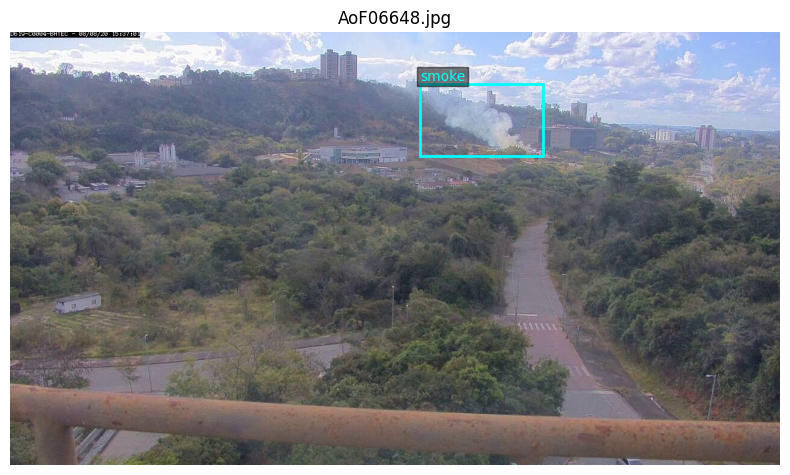

Vorhandene Klassen: {'smoke'}

In [9]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def show_sample(images_dir, labels_dir, idx=None):
    names = sorted(f for f in os.listdir(images_dir) if f.endswith(".jpg"))
    # Ein zufälliges Bild auswählen
    # name  = names[idx] if idx is not None else random.choice(names)
    # Ein ausgesuchtes Bild
    name = "AoF06648.jpg"
    print("Opening image file:", name)
    stem  = os.path.splitext(name)[0]

    img  = Image.open(os.path.join(images_dir, name)).convert("RGB")
    W, H = img.size

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img)
    ax.set_title(name)

    label_path = os.path.join(labels_dir, stem + ".txt")
    classes_present = set()

    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                cls = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:5])
                x1 = (xc - bw / 2) * W
                y1 = (yc - bh / 2) * H
                color = CLASS_COLORS[cls]
                ax.add_patch(patches.Rectangle(
                    (x1, y1), bw * W, bh * H,
                    linewidth=2, edgecolor=color, facecolor="none"
                ))
                ax.text(x1, max(0, y1 - 6), CLASS_NAMES[cls],
                        color=color, fontsize=10,
                        bbox=dict(facecolor="black", alpha=0.5, pad=2))
                classes_present.add(CLASS_NAMES[cls])

    ax.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Vorhandene Klassen: {classes_present or 'keine'}")


show_sample(TRAIN_IMAGES, TRAIN_LABELS)


# Von der Klassifikation zur Detektion: Faster R-CNN

## Detektion vs. Klassifikation

| Aufgabe         | Ausgabe                    | Beantwortete Frage |
|-----------------|----------------------------|--------------------|
| Klassifikation  | Klassenlabel               | *Was* ist im Bild? |
| Objektdetektion | Begrenzungsrahmen + Labels | *Was* und *wo*?    |

## Architekturübersicht

ResNet-50 allein ist ein Klassifikator — ein Label für das gesamte Bild.
Als Backbone in Faster R-CNN eingebunden wird es zum **Detektor**: es
lokalisiert und beschriftet mehrere Objekte pro Bild mit
Begrenzungsrahmen.

<figure>
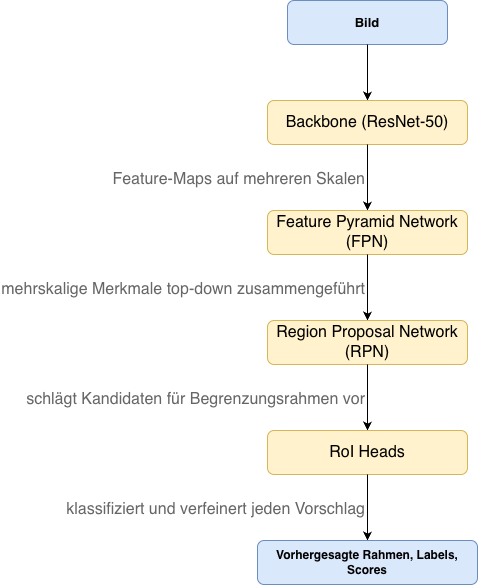
<figcaption aria-hidden="true">Faster R-CNN-Pipeline: Das Eingabebild
durchläuft den ResNet-50-Backbone und das Feature Pyramid Network (FPN),
welches Merkmalskarten auf mehreren Skalen erzeugt. Das Region Proposal
Network (RPN) schlägt ~2 000 Kandidaten-Begrenzungsrahmen vor; die
RoI-Heads klassifizieren und verfeinern jeden Vorschlag zu den
endgültigen Detektionsergebnissen (Rahmen, Labels, Scores).</figcaption>
</figure>

## Anpassung für Feuer/Rauch

`torchvision` stellt ein fertiges `fasterrcnn_resnet50_fpn` bereit. Die
einzige nötige Änderung ist der Box-Prediktor-Kopf, der Scores für
unsere 2 Klassen (Rauch, Feuer) statt COCO Klassen ausgeben muss.

``` python
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
    in_features, num_classes=3)
```

Das Backbone behält seine vortrainierten Gewichte. Nur der neue
`FastRCNNPredictor` startet von Grund auf.

# Aufbau der Detektionspipeline

## Aufgabe 6 — `DFireDetectionDataset`

> **Aufgabe 6 — Dataset-Klasse**
>
> Implementieren Sie `DFireDetectionDataset(Dataset)`. Für jedes Bild
> muss sie:
>
> 1.  Das Bild mit OpenCV laden und BGR → RGB konvertieren.
> 2.  Die YOLO-Label-Datei parsen und normalisierte `(x_c, y_c, w, h)`
>     in absolute Pixelkoordinaten `(x1, y1, x2, y2)` umrechnen.
> 3.  `(image_tensor, target)` zurückgeben, wobei `target` ein Dict mit
>     den Schlüsseln `boxes` (float32), `labels` (int64) und `image_id`
>     ist.
>
> YOLO-Klasse 0 (Rauch) → Label 1 und Klasse 1 (Feuer) → Label 2
> abbilden. Label 0 ist von torchvision für den Hintergrund reserviert.

In [10]:
import os
import glob
import cv2
import torch
from torch.utils.data import Dataset


def yolo_to_xyxy(xc, yc, bw, bh, W, H):
    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H
    return [x1, y1, x2, y2]


class DFireDetectionDataset(Dataset):
    CLASS_MAP = {0: 1, 1: 2}   # Rauch → 1, Feuer → 2

    def __init__(self, images_dir, labels_dir):
        self.images     = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))
        self.labels_dir = labels_dir

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        img      = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        H, W     = img.shape[:2]

        stem       = os.path.splitext(os.path.basename(img_path))[0]
        label_path = os.path.join(self.labels_dir, stem + ".txt")

        boxes, labels = [], []
        if os.path.exists(label_path):
            with open(label_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls = int(parts[0])
                    xc, yc, bw, bh = map(float, parts[1:5])
                    if bw < 1e-4 or bh < 1e-4:
                        continue
                    boxes.append(yolo_to_xyxy(xc, yc, bw, bh, W, H))
                    labels.append(self.CLASS_MAP[cls])

        boxes  = torch.as_tensor(boxes,  dtype=torch.float32).reshape(-1, 4)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes":    boxes,
            "labels":   labels,
            "image_id": torch.tensor([idx]),
        }
        img_tensor = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
        return img_tensor, target

Datensatzgröße: 17221 Bilder
Bildtensor: torch.Size([3, 720, 1280])  dtype=torch.float32
Rahmen:     torch.Size([1, 4])  → tensor([[1125.,  139., 1215.,  218.]])
Labels:     [1]  (1=Rauch, 2=Feuer)

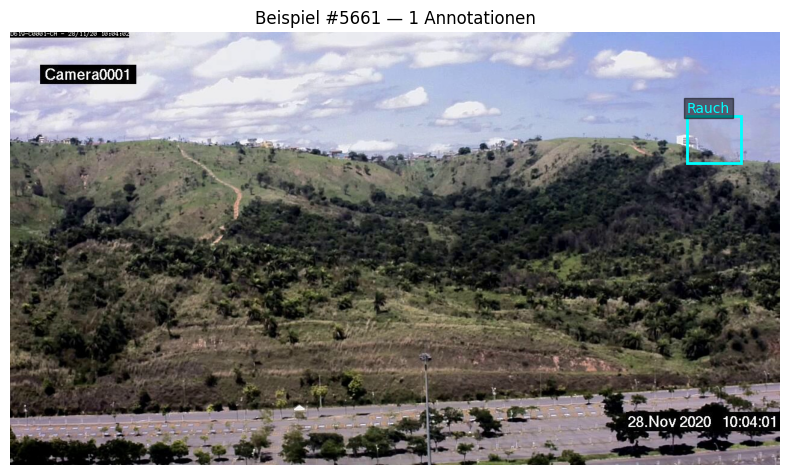

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

ds = DFireDetectionDataset(TRAIN_IMAGES, TRAIN_LABELS)
print(f"Datensatzgröße: {len(ds)} Bilder")

# Zufälliges Beispiel laden
idx  = random.randint(0, len(ds))
img_tensor, target = ds[idx]

print(f"Bildtensor: {img_tensor.shape}  dtype={img_tensor.dtype}")
print(f"Rahmen:     {target['boxes'].shape}  → {target['boxes']}")
print(f"Labels:     {target['labels'].tolist()}  (1=Rauch, 2=Feuer)")

# Visualisierung
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img_tensor.permute(1, 2, 0))

CLASS_COLORS = {1: "cyan", 2: "red"}
CLASS_NAMES  = {1: "Rauch", 2: "Feuer"}

for box, label in zip(target["boxes"], target["labels"]):
    x1, y1, x2, y2 = box.tolist()
    color = CLASS_COLORS[label.item()]
    ax.add_patch(patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor=color, facecolor="none"
    ))
    ax.text(x1, max(0, y1 - 6), CLASS_NAMES[label.item()],
            color=color, fontsize=10,
            bbox=dict(facecolor="black", alpha=0.5, pad=2))

ax.set_title(f"Beispiel #{idx} — {len(target['boxes'])} Annotationen")
ax.axis("off")
plt.tight_layout()
plt.show()

## Aufgabe 7 — DataLoader

> **Aufgabe 7 — DataLoader-Setup**
>
> Verpacken Sie den Datensatz in einen `DataLoader`. Die Objektdetektion
> erfordert eine benutzerdefinierte `collate_fn`, da jedes Bild eine
> unterschiedliche Anzahl von Begrenzungsrahmen haben kann — sie können
> nicht wie Bilder in einen einzelnen Tensor gestapelt werden.
>
> Verwenden Sie für schnelle Iterationen eine Teilmenge von z.B. 1000
> Trainingsbildern. Drucken Sie die Anzahl der Train-Batches und die
> Gesamtzahl der Val-Bilder aus.

In [12]:
from torch.utils.data import DataLoader, Subset
import random

def collate_fn(batch):
    return tuple(zip(*batch))


train_ds = DFireDetectionDataset(TRAIN_IMAGES, TRAIN_LABELS)
val_ds   = DFireDetectionDataset(VAL_IMAGES,   VAL_LABELS)

random.seed(42)
train_subset = Subset(train_ds, random.sample(range(len(train_ds)), 800))
val_subset = Subset(val_ds, random.sample(range(len(val_ds)), 200))

train_loader = DataLoader(train_subset, batch_size=4, shuffle=True,
                          num_workers=0, collate_fn=collate_fn)
val_loader   = DataLoader(val_subset, batch_size=2, shuffle=False,
                          num_workers=0, collate_fn=collate_fn)

print(f"Train-Batch Anzahl × Batch Size: {len(train_loader)} × 4")
print(f"Anzahl Val-Bilder              : {len(val_subset)}")

Train-Batch Anzahl × Batch Size: 200 × 4
Anzahl Val-Bilder              : 200

## Aufgabe 8 — Modell-Setup

> **Aufgabe 8 — Faster-R-CNN-Kopf tauschen**
>
> Laden Sie `fasterrcnn_resnet50_fpn(weights="DEFAULT")`, tauschen Sie
> den Box-Prediktor gegen einen mit 3 Ausgabeklassen und frieren Sie das
> gesamte Backbone ein. Drucken Sie aus, welcher Anteil der Parameter
> trainiert wird.

In [13]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def make_detector(num_classes):
    model       = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = make_detector(num_classes=3).to(device)

for param in model.backbone.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainiere {trainable:,} / {total:,} Parameter  ({100 * trainable / total:.1f}%)")

Trainiere 14,504,990 / 41,304,286 Parameter  (35.1%)

## Aufgabe 9 — Trainingsschleife

> **Aufgabe 9 — `train_one_epoch`**
>
> Implementieren Sie
> `train_one_epoch(model, loader, optimizer, device)`.
>
> Im Detektionsmodus (`model.train()`) gibt die Übergabe von
> `(images, targets)` an das Modell ein `loss_dict` mit separaten
> Verlusten für RPN und RoI-Heads zurück. Summieren Sie sie zu einem
> Skalar, rufen Sie `.backward()` auf und machen Sie einen
> Optimizer-Schritt. Geben Sie den durchschnittlichen Verlust pro Batch
> zurück.

In [14]:
from tqdm import tqdm

def train_one_epoch(model, loader, optimizer, device):
    model.train()
    running = 0.0

    for images, targets in tqdm(loader, desc="train", leave=False):
        images  = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss      = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running += loss.item()

    return running / max(1, len(loader))


## Aufgabe 10 — Validierungsschleife

> **Aufgabe 10 — `validate_one_epoch`**
>
> Implementieren Sie `validate_one_epoch(model, loader, device)`.
>
> Es gibt eine subtile Anforderung: Faster R-CNN von `torchvision` gibt
> nur dann ein `loss_dict` zurück, wenn es sich im **Trainings-Modus**
> befindet und Targets empfängt. Um den Validierungsverlust ohne
> Gewichtsaktua­lisierung zu berechnen, rufen Sie `model.train()` auf,
> aber umschließen Sie die Schleife mit `@torch.no_grad()`, damit keine
> Gradienten alloziert werden. Geben Sie den durchschnittlichen Verlust
> pro Batch zurück.

In [15]:
@torch.no_grad()
def validate_one_epoch(model, loader, device):
    model.train()    # nötig für loss_dict — no_grad verhindert Gradientenspeicherung
    running = 0.0

    for images, targets in tqdm(loader, desc="val  ", leave=False):
        images  = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        running  += sum(loss_dict.values()).item()

    model.eval()
    return running / max(1, len(loader))

> **Warum `model.train()` innerhalb einer Validierungsfunktion?**
>
> `model.eval()` schaltet torchvision-Detektoren in den Inferenz-Modus —
> sie geben dann vorhergesagte Rahmen statt Verluste zurück. Es gibt
> keinen eingebauten “Eval-mit-Verlust”-Modus, daher ist die übliche
> Lösung `model.train()` + `torch.no_grad()`. Der Dekorator verhindert,
> dass PyTorch den Berechnungsgraphen aufbaut, sodass der
> Speicherverbrauch identisch mit einem echten Eval-Durchlauf ist.

# Training & Überwachung

In [ ]:
from datetime import datetime

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005, momentum=0.9, weight_decay=5e-4
)

num_epochs = 3
for epoch in range(num_epochs):
    t0         = datetime.now()
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    val_loss   = validate_one_epoch(model, val_loader, device)
    elapsed    = (datetime.now() - t0).total_seconds()
    print(f"Epoch {epoch + 1:2d}/{num_epochs}  "
          f"train={train_loss:.4f}  val={val_loss:.4f}  ({elapsed:.0f}s)")

torch.save(model.state_dict(), "dfire_fasterrcnn.pth")
print("Gespeichert: dfire_fasterrcnn.pth")

## Aufgabe 11 — Überanpassung demonstrieren

> **Aufgabe 11 — Überanpassungs-Experiment**
>
> Überanpassung (Overfitting) tritt auf, wenn ein Modell Trainingsdaten
> auswendig lernt statt verallgemeinerbare Merkmale zu erlernen: Der
> Trainingsverlust sinkt weiter, während der Validierungsverlust
> stagniert oder steigt.
>
> Richten Sie zwei Läufe ein und zeigen Sie deren Verlustkurven
> nebeneinander:
>
> | Lauf                  | Trainingsset-Größe | Epochen |
> |-----------------------|--------------------|---------|
> | A — **Überanpassung** | 50 Bilder          | 40      |
> | B — **Normal**        | 2 000 Bilder       | 10      |
>
> Initialisieren Sie für jeden Lauf ein neues Modell und einen neuen
> Optimizer. Zeichnen Sie `(train_loss, val_loss)` nach jeder Epoche
> auf. Plotten Sie beide Kurven auf denselben Achsen mit `matplotlib`.
>
> Welche Form erwarten Sie für Lauf A? Was sagt die Lücke zwischen
> Train- und Val-Verlust aus?

In [31]:
import matplotlib.pyplot as plt


def run_experiment(n_train, n_epochs, seed=0):
    """Trainiert einen neuen Detektor auf n_train Bildern für n_epochs. Gibt Verlaufshistorie zurück."""
    random.seed(seed)
    subset = Subset(train_ds, random.sample(range(len(train_ds)), n_train))
    loader = DataLoader(subset, batch_size=4, shuffle=True,
                        num_workers=0, collate_fn=collate_fn)

    m = make_detector(num_classes=3).to(device)
    for param in m.backbone.parameters():
        param.requires_grad = False

    opt = torch.optim.SGD(
        [p for p in m.parameters() if p.requires_grad],
        lr=0.005, momentum=0.9, weight_decay=5e-4
    )

    history = {"train": [], "val": []}
    for epoch in range(n_epochs):
        history["train"].append(train_one_epoch(m, loader, opt, device))
        history["val"].append(validate_one_epoch(m, val_loader, device))
        print(f"  epoch {epoch + 1:2d}  train={history['train'][-1]:.3f}"
              f"  val={history['val'][-1]:.3f}")

    return history


print("=== Lauf A: 50 Bilder, 40 Epochen ===")
# hist_overfit = run_experiment(n_train=50,   n_epochs=40)

print("\n=== Lauf B: 2000 Bilder, 10 Epochen ===")
hist_normal  = run_experiment(n_train=2000, n_epochs=10)


=== Lauf A: 50 Bilder, 40 Epochen ===

=== Lauf B: 2000 Bilder, 10 Epochen ===

  epoch  1  train=0.215  val=0.192

  epoch  2  train=0.190  val=0.186

  epoch  3  train=0.183  val=0.189

  epoch  4  train=0.177  val=0.183

...

  epoch  6  train=0.172  val=0.194

  epoch  7  train=0.170  val=0.180

  epoch  8  train=0.165  val=0.183

  epoch  9  train=0.163  val=0.184

  epoch 10  train=0.160  val=0.176

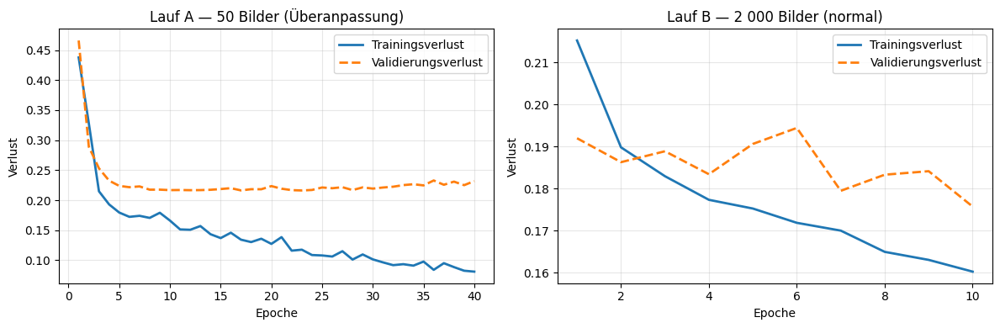

In [32]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, hist, title in zip(
    axes,
    [hist_overfit, hist_normal],
    ["Lauf A — 50 Bilder (Überanpassung)", "Lauf B — 2 000 Bilder (normal)"],
):
    epochs = range(1, len(hist["train"]) + 1)
    ax.plot(epochs, hist["train"], label="Trainingsverlust", linewidth=2)
    ax.plot(epochs, hist["val"],   label="Validierungsverlust", linewidth=2, linestyle="--")
    ax.set_xlabel("Epoche")
    ax.set_ylabel("Verlust")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


-   **Lauf A:** Trainingsverlust nähert sich null; Validierungsverlust
    divergiert — das Modell hat 50 Bilder auswendig gelernt und kann
    nicht verallgemeinern. Das ist die klassische
    Überanpassungs-Signatur.
-   **Lauf B:** Beide Kurven sinken zusammen und konvergieren annähernd
    — das Modell lernt verallgemeinerbare Merkmale.
-   Die **Lücke** zwischen Train- und Val-Verlust ist das praktische Maß
    für den Überanpassungsgrad. Gegenmaßnahmen: mehr Daten,
    Datenerweiterung (Data Augmentation), Weight Decay, Dropout oder
    frühzeitiges Stoppen (Early Stopping).

# Inferenz & Auswertung

## Aufgabe 12 — Vorhersage auf einem einzelnen Bild

> **Aufgabe 12 — Inferenzfunktion**
>
> Laden Sie die gespeicherten Gewichte und schreiben Sie
> `predict(model, img_path, device, score_thresh=0.5)`.
>
> Im Eval-Modus (`model.eval()`) akzeptiert das Modell `[image_tensor]`
> und gibt `[{"boxes", "labels", "scores"}]` zurück. Filtern Sie nach
> `score_thresh` und geben Sie das Bild-Array zusammen mit den
> gefilterten Detektionen zurück.

In [18]:
import cv2 

model.load_state_dict(torch.load("Daten/ResNet/models/dfire_fasterrcnn_full.pth", map_location=device))
model.eval()

CLASS_NAMES = {1: "smoke", 2: "fire"}

@torch.inference_mode()
def predict(model, img_path, device, score_thresh=0.5):
    img    = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0

    out  = model([tensor.to(device)])[0]
    keep = out["scores"] >= score_thresh

    return {
        "image":  img,
        "boxes":  out["boxes"][keep].cpu(),
        "labels": out["labels"][keep].cpu(),
        "scores": out["scores"][keep].cpu(),
    }

## Aufgabe 13 — Vorhersagen visualisieren

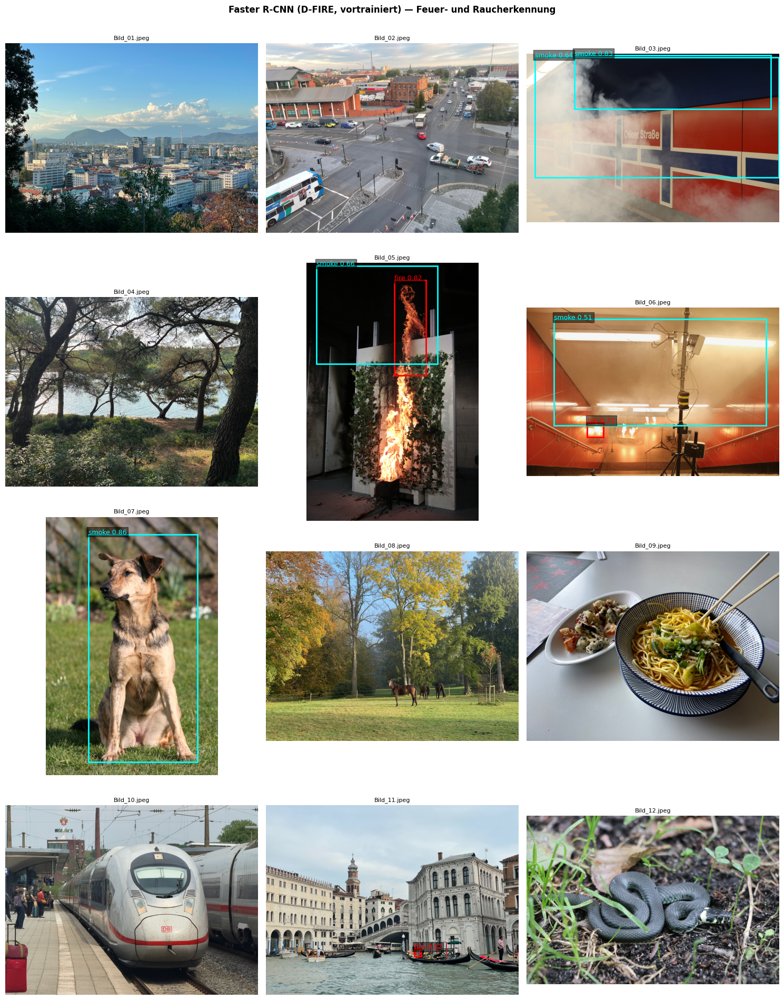

In [25]:
# Bereitgestelltes vortrainiertes D-FIRE-Modell laden
dfire_full = make_detector(num_classes=3)
dfire_full.load_state_dict(
    torch.load("Daten/ResNet/models/dfire_fasterrcnn_full.pth", map_location="cpu")
)
dfire_full.eval()

dfire_paths = sorted(glob.glob("Daten/ResNet/Bild_??.jpeg"))

ncols = min(3, len(dfire_paths))
nrows = (len(dfire_paths) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
axes = axes.flatten()

for ax, path in zip(axes, dfire_paths):
    result = predict(dfire_full, path, torch.device("cpu"))
    ax.imshow(result["image"])
    ax.axis("off")
    ax.set_title(os.path.basename(path), fontsize=8)

    for box, label, score in zip(result["boxes"], result["labels"], result["scores"]):
        x1, y1, x2, y2 = box.tolist()
        cls   = label.item()
        color = CLASS_COLORS.get(cls, "white")
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        ))
        ax.text(x1, max(0, y1 - 6),
                f"{CLASS_NAMES[cls]} {score:.2f}",
                color=color, fontsize=9,
                bbox=dict(facecolor="black", alpha=0.5, pad=2))

for ax in axes[len(dfire_paths):]:
    ax.axis("off")

plt.suptitle("Faster R-CNN (D-FIRE, vortrainiert) — Feuer- und Raucherkennung", fontweight="bold")
plt.tight_layout()
plt.show()


# Modellvergleich mit der Konfusionsmatrix

## Die Konfusionsmatrix für Detektion anpassen

Eine Standard-Konfusionsmatrix setzt ein Label pro Sample voraus.
Objektdetektion ist anders: Jedes Bild enthält eine variable Anzahl
vorhergesagter Rahmen und Ground-Truth-Rahmen.

## IoU — Intersection over Union

**IoU** (*Intersection over Union*) misst, wie stark sich zwei
Begrenzungsrahmen überlappen:

$$\text{IoU} = \frac{|A \cap B|}{|A \cup B|}$$

      ┌──────────┐
      │    A     │
      │   ┌──────┼────┐
      │   │  ∩   │ B  │
      └───┼──────┘    │
          └───────────┘

      IoU = Fläche(∩) / Fläche(∪)

-   **IoU = 1,0** — Rahmen sind identisch
-   **IoU = 0,0** — Rahmen überlappen sich nicht
-   **IoU ≥ 0,5** — Standardschwellenwert: eine Vorhersage gilt als
    Treffer

## IoU-Matching

Bevor wir fragen können *“hat das Modell die richtige Klasse
vorhergesagt?”*, müssen wir zunächst fragen *“welche Vorhersage
entspricht welcher Ground Truth?”*. Das wird durch **IoU-Matching**
beantwortet:

1.  Paarweisen IoU zwischen allen vorhergesagten Rahmen und allen
    Ground-Truth-Rahmen in einem Bild berechnen.
2.  Jede Vorhersage gierig dem Ground-Truth-Rahmen zuordnen, mit dem sie
    sich am stärksten überschneidet, sofern IoU ≥ einem Schwellenwert
    (typischerweise 0,5). Jeder Ground-Truth-Rahmen kann nur einmal
    zugeordnet werden.
3.  Zugeordnete Paare anhand ihrer Klassenlabels bewerten.
4.  Nicht zugeordnete Vorhersagen zählen als **falsch positive**
    (vorhergesagte Klasse vs. Hintergrund).
5.  Nicht zugeordnete Ground Truths zählen als **falsch negative**
    (wahre Klasse vs. Hintergrund).

Das Ergebnis ist eine **(num_classes + 1) × (num_classes + 1)**-Matrix
mit einer Hintergrunds-Zeile und -Spalte.

                   Vorhergesagt
                  HG  Rauch  Feuer
               ┌──────────────────
    G.-Wahrh. HG │  ·    FP    FP
            Rauch │  FN   TP  Verw.
            Feuer │  FN  Verw.  TP

## Aufgabe 14 — `build_confusion_matrix` implementieren

> **Aufgabe 14 — Konfusionsmatrix für Detektion**
>
> Implementieren Sie
> `build_confusion_matrix(model, loader, device, iou_thresh=0.5, score_thresh=0.5)`.
>
> Schritte pro Bild:
>
> 1.  Modell im Eval-Modus ausführen, um vorhergesagte Rahmen, Labels
>     und Scores zu erhalten.
> 2.  Vorhersagen unterhalb von `score_thresh` herausfiltern.
> 3.  `torchvision.ops.box_iou` verwenden, um eine `[n_pred, n_gt]`
>     IoU-Matrix zu berechnen.
> 4.  Vorhersage-Ground-Truth-Paare gierig zuordnen (höchster IoU
>     zuerst, jeder Index einmal).
> 5.  Für zugeordnete Paare mit IoU ≥ `iou_thresh`:
>     `(gt_label, pred_label)` aufzeichnen.
> 6.  Für nicht zugeordnete Vorhersagen: `(0, pred_label)` aufzeichnen —
>     falsch positiv.
> 7.  Für nicht zugeordnete Ground Truths: `(gt_label, 0)` aufzeichnen —
>     falsch negativ.
>
> Ein `numpy`-Array der Form `(num_classes, num_classes)` zurückgeben,
> Index 0 = Hintergrund.

In [27]:
import numpy as np
from torchvision.ops import box_iou
from tqdm import tqdm


def build_confusion_matrix(model, loader, device,
                           iou_thresh=0.5, score_thresh=0.5, num_classes=3):
    matrix = np.zeros((num_classes, num_classes), dtype=int)
    tn_count       = 0  # Bilder: GT leer UND keine Vorhersage
    empty_gt_count = 0  # Bilder: GT leer (gesamt)

    model.eval()
    with torch.no_grad():
        for images, targets in tqdm(loader, desc="eval", leave=False):
            images = [img.to(device) for img in images]
            preds  = model(images)

            for pred, target in zip(preds, targets):
                gt_boxes  = target["boxes"].cpu()
                gt_labels = target["labels"].cpu()

                keep        = pred["scores"].cpu() >= score_thresh
                pred_boxes  = pred["boxes"].cpu()[keep]
                pred_labels = pred["labels"].cpu()[keep]

                # True-Negative-Tracking auf Bildebene
                if len(gt_boxes) == 0:
                    empty_gt_count += 1
                    if len(pred_boxes) == 0:
                        tn_count += 1
                    # Kein Eintrag in die Matrix — kein GT-Objekt vorhanden
                    continue

                matched_pred = set()
                matched_gt   = set()

                if len(pred_boxes) > 0:
                    ious = box_iou(pred_boxes, gt_boxes)   # [n_pred, n_gt]

                    # Alle Paare nach IoU absteigend sortieren, dann zuordnen
                    pairs = sorted(
                        [(i, j) for i in range(len(pred_boxes))
                                 for j in range(len(gt_boxes))],
                        key=lambda x: -ious[x[0], x[1]].item()
                    )
                    for pi, gi in pairs:
                        if pi in matched_pred or gi in matched_gt:
                            continue
                        if ious[pi, gi] >= iou_thresh:
                            matrix[gt_labels[gi].item(),
                                   pred_labels[pi].item()] += 1
                            matched_pred.add(pi)
                            matched_gt.add(gi)

                # Nicht zugeordnete Vorhersagen → falsch positiv (Zeile = Hintergrund = 0)
                for pi in range(len(pred_boxes)):
                    if pi not in matched_pred:
                        matrix[0, pred_labels[pi].item()] += 1

                # Nicht zugeordnete Ground Truths → falsch negativ (Spalte = Hintergrund = 0)
                for gi in range(len(gt_boxes)):
                    if gi not in matched_gt:
                        matrix[gt_labels[gi].item(), 0] += 1

    print(f"True Negatives: {tn_count} / {empty_gt_count} "
          f"Bilder ohne Objekte korrekt als leer erkannt "
          f"({100 * tn_count / max(empty_gt_count, 1):.1f} %)")
    return matrix


In [28]:
def plot_confusion_matrix(matrix, title="", class_names=None):
    if class_names is None:
        class_names = ["Hintergrund", "Rauch", "Feuer"]

    row_sums  = matrix.sum(axis=1, keepdims=True)
    norm      = matrix / np.where(row_sums == 0, 1, row_sums)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(title, fontsize=13, fontweight="bold")

    for ax, data, fmt, subtitle in zip(
        axes,
        [matrix, norm],
        ["d", ".2f"],
        ["Anzahl", "Zeilen-normalisiert (Recall je Klasse)"],
    ):
        im = ax.imshow(data, cmap="Blues", vmin=0)
        ax.set_xticks(range(len(class_names)))
        ax.set_yticks(range(len(class_names)))
        ax.set_xticklabels(class_names, rotation=45, ha="right")
        ax.set_yticklabels(class_names)
        ax.set_xlabel("Vorhergesagt")
        ax.set_ylabel("Ground Truth")
        ax.set_title(subtitle)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        for r in range(len(class_names)):
            for c in range(len(class_names)):
                val = data[r, c]
                txt = f"{val:{fmt}}"
                color = "white" if val > data.max() * 0.6 else "black"
                ax.text(c, r, txt, ha="center", va="center",
                        fontsize=9, color=color)

    plt.tight_layout()
    plt.show()

In [29]:
def build_per_image_confusion(model, loader, device,
                              score_thresh=0.5, num_classes=3):
    """Binary 2×2 confusion matrix per foreground class, counted at image level.

    matrices[c] has rows = GT (absent / present) and cols = pred (absent / present).
    """
    fg = num_classes - 1
    matrices = np.zeros((fg, 2, 2), dtype=int)

    model.eval()
    with torch.no_grad():
        for images, targets in tqdm(loader, desc="eval (per-Bild)", leave=False):
            images = [img.to(device) for img in images]
            preds  = model(images)

            for pred, target in zip(preds, targets):
                gt_labels   = target["labels"].cpu()
                keep        = pred["scores"].cpu() >= score_thresh
                pred_labels = pred["labels"].cpu()[keep]

                for c_idx, c in enumerate(range(1, num_classes)):
                    gt_present   = int((gt_labels == c).any())
                    pred_present = int((pred_labels == c).any())
                    matrices[c_idx, gt_present, pred_present] += 1

    return matrices


def plot_per_image_confusion(matrices, title="", class_names=None):
    if class_names is None:
        class_names = ["Rauch", "Feuer"]

    labels = ["kein Objekt", "vorhanden"]
    n = len(class_names)
    fig, axes = plt.subplots(2, n, figsize=(5 * n, 9), squeeze=False)
    fig.suptitle(f"{title} — Konfusionsmatrix pro Bild", fontsize=13, fontweight="bold")

    for c_idx, cname in enumerate(class_names):
        mat      = matrices[c_idx]
        row_sums = mat.sum(axis=1, keepdims=True)
        norm     = mat / np.where(row_sums == 0, 1, row_sums)

        for row, (data, fmt, subtitle) in enumerate(zip(
            [mat, norm],
            ["d", ".2f"],
            [f"{cname} — Anzahl", f"{cname} — Zeilen-normalisiert"],
        )):
            ax = axes[row, c_idx]
            im = ax.imshow(data, cmap="Greens", vmin=0)
            ax.set_xticks([0, 1])
            ax.set_yticks([0, 1])
            ax.set_xticklabels(labels, rotation=20, ha="right")
            ax.set_yticklabels(labels)
            ax.set_xlabel("Vorhergesagt")
            ax.set_ylabel("Ground Truth")
            ax.set_title(subtitle)
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            for r in range(2):
                for c in range(2):
                    val   = data[r, c]
                    color = "white" if val > data.max() * 0.6 else "black"
                    ax.text(c, r, f"{val:{fmt}}", ha="center", va="center",
                            fontsize=12, color=color)

    plt.tight_layout()
    plt.show()


## Aufgabe 15 — Mehrere Checkpoints vergleichen

> **Aufgabe 15 — Modellvergleich nebeneinander**
>
> Schreiben Sie `evaluate_checkpoint(pth_path, val_loader, device)`, das
> eine gespeicherte `.pth`-Datei in einen neuen Detektor lädt und dessen
> Konfusionsmatrix zurückgibt.
>
> Füllen Sie dann das `checkpoints`-Dict mit Ihrer eigenen `.pth`-Datei
> und etwaigen Dateien anderer Studierender oder Referenzmodelle. Die
> Schleife plottet für jedes eine normalisierte Konfusionsmatrix.
> Vergleichen Sie:
>
> -   Welches Modell verwechselt Rauch und Feuer am häufigsten?
> -   Welches hat die niedrigste Falsch-Positiv-Rate für den
>     Hintergrund?
> -   Verbessert mehr Trainingszeit (mehr Epochen) die Diagonale?

True Negatives: 64 / 94 Bilder ohne Objekte korrekt als leer erkannt (68.1 %)

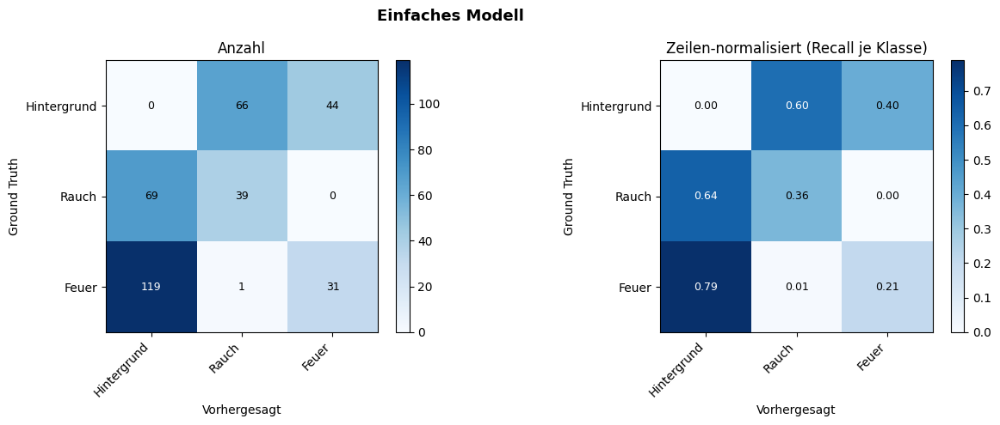

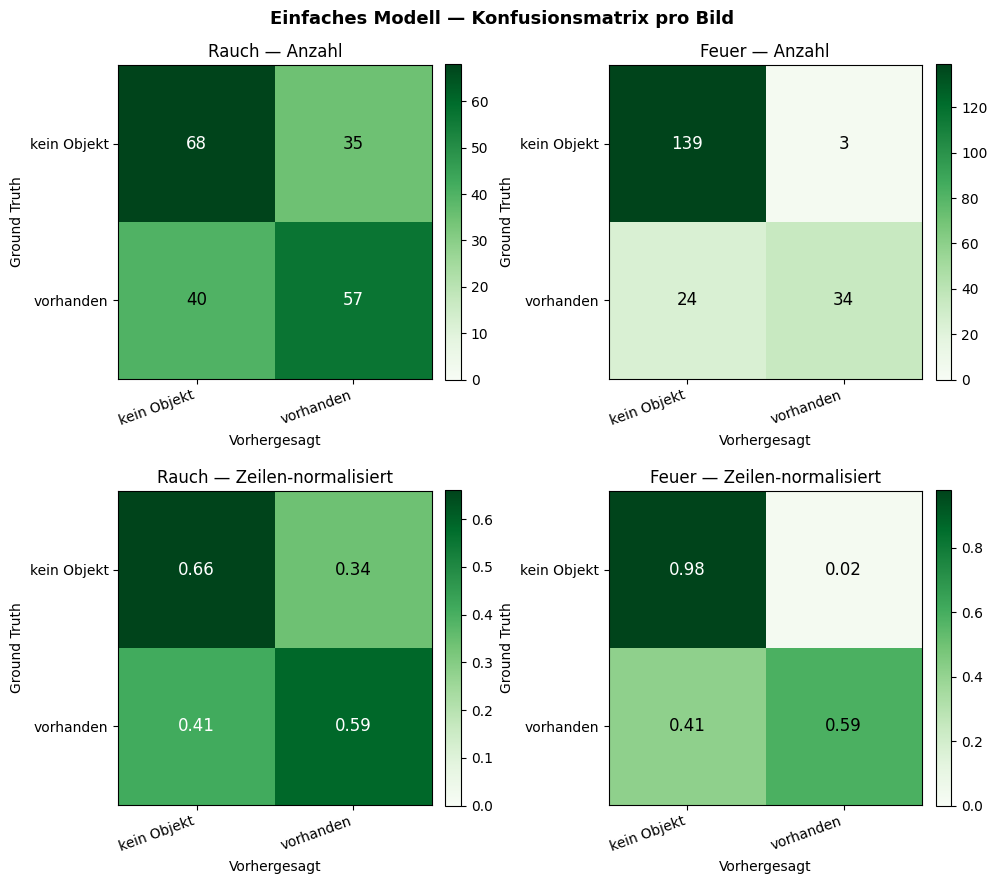

True Negatives: 67 / 94 Bilder ohne Objekte korrekt als leer erkannt (71.3 %)

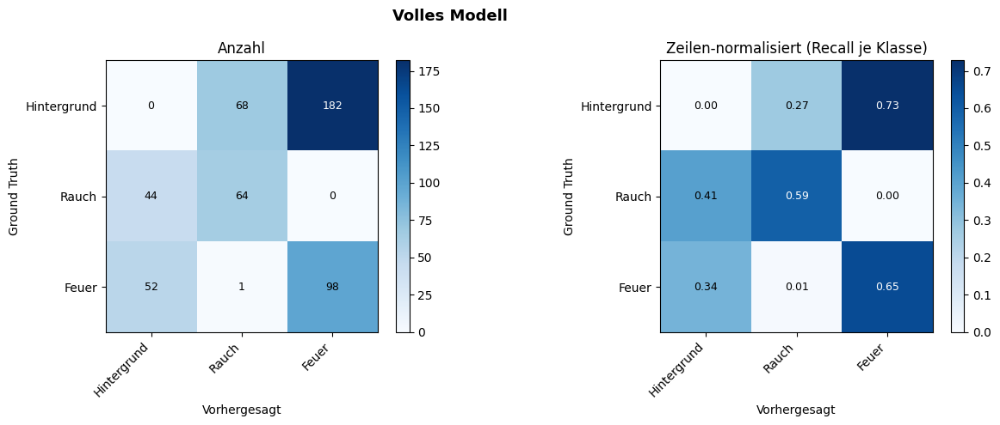

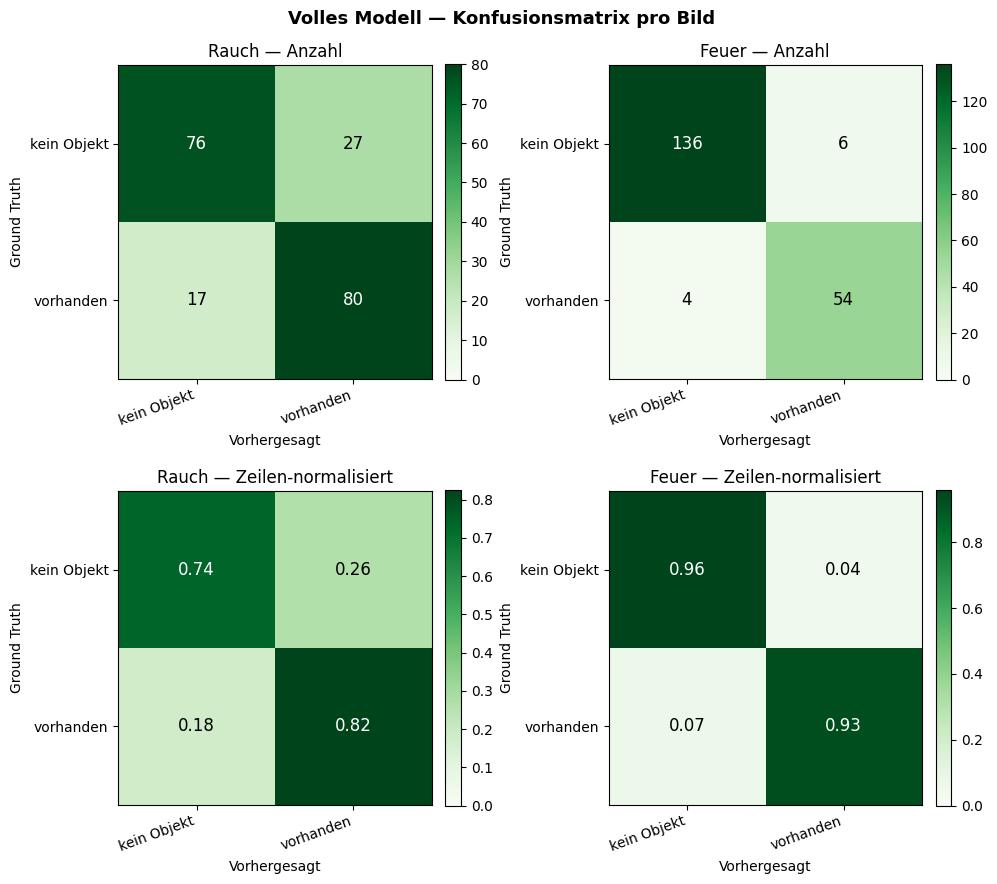

In [30]:

def evaluate_checkpoint(pth_path, val_loader, device, **kwargs):
    m = make_detector(num_classes=3).to(device)
    m.load_state_dict(torch.load(pth_path, map_location=device))
    box_matrix = build_confusion_matrix(m, val_loader, device, **kwargs)
    img_matrix = build_per_image_confusion(m, val_loader, device,
                                           score_thresh=kwargs.get("score_thresh", 0.5))
    return box_matrix, img_matrix


# --- Eigene .pth-Dateien hier eintragen ---
checkpoints = {
    "Einfaches Modell": "Daten/ResNet/models/dfire_fasterrcnn_small.pth",
    "Volles Modell":    "Daten/ResNet/models/dfire_fasterrcnn_full.pth",
    # "Student A": "student_a.pth",
    # "Referenz (vollständig feinabgestimmt)": "reference.pth",
}

for name, path in checkpoints.items():
    if not os.path.exists(path):
        print(f"Überspringe '{name}': Datei nicht gefunden ({path})")
        continue
    box_matrix, img_matrix = evaluate_checkpoint(path, val_loader, device)
    plot_confusion_matrix(box_matrix, title=name)
    plot_per_image_confusion(img_matrix, title=name)
